<a href="https://colab.research.google.com/github/shaneduhh/CSCI218_Group_Project/blob/main/CSCI218_Group_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
import heapq
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

In [14]:
UNBLOCKED = 0
BLOCKED = 1
START = 2
GOAL = 3
VISITED = 4
PATH = 5

In [15]:
def create_grid(size=25, obstacle_prob=0.25, seed=None):
    if seed is not None:
        np.random.seed(seed)
    grid = (np.random.rand(size, size) < obstacle_prob).astype(int)
    start = (0, 0)
    goal = (size - 1, size - 1)
    grid[start] = UNBLOCKED
    grid[goal] = UNBLOCKED
    return grid, start, goal

In [16]:
def heuristic(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])

In [17]:
def get_neighbors(grid, node):
    rows, cols = grid.shape
    r, c = node
    directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    neighbors = []
    for dr, dc in directions:
        nr, nc = r + dr, c + dc
        if 0 <= nr < rows and 0 <= nc < cols and grid[nr, nc] != BLOCKED:
            neighbors.append((nr, nc))
    return neighbors

In [18]:
def reconstruct_path(came_from, current):
    path = []
    while current in came_from:
        path.append(current)
        current = came_from[current]
    path.append(current)
    return path[::-1]

In [19]:
def run_search(grid, start, goal, use_astar=True):
    start_time = time.perf_counter()

    open_set = []
    heapq.heappush(open_set, (0, start))

    came_from = {}
    g_score = {start: 0}
    visited = set()
    nodes_explored = 0

    while open_set:
        _, current = heapq.heappop(open_set)

        if current in visited:
            continue
        visited.add(current)
        nodes_explored += 1

        if current == goal:
            elapsed_ms = (time.perf_counter() - start_time) * 1000
            path = reconstruct_path(came_from, current)
            return path, visited, nodes_explored, elapsed_ms

        for neighbor in get_neighbors(grid, current):
            tentative_g = g_score[current] + 1
            if tentative_g < g_score.get(neighbor, float('inf')):
                came_from[neighbor] = current
                g_score[neighbor] = tentative_g
                h = heuristic(neighbor, goal) if use_astar else 0
                f_score = tentative_g + h
                heapq.heappush(open_set, (f_score, neighbor))

    elapsed_ms = (time.perf_counter() - start_time) * 1000
    return None, visited, nodes_explored, elapsed_ms

In [20]:
def visualize_grid_comparison(grid, start, goal, dijkstra_res, astar_res):
    d_path, d_visited, d_nodes, d_time = dijkstra_res
    a_path, a_visited, a_nodes, a_time = astar_res

    cmap = colors.ListedColormap(['white', 'black', 'green', 'red', 'lightblue', 'gold'])
    bounds = [0, 1, 2, 3, 4, 5, 6]
    norm = colors.BoundaryNorm(bounds, cmap.N)

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    # Panel 1: Initial Grid
    init_grid = grid.copy()
    init_grid[start] = START
    init_grid[goal] = GOAL
    axes[0].imshow(init_grid, cmap=cmap, norm=norm)
    axes[0].set_title("Initial 2D Grid Environment\n(Green: Start, Red: Goal, Black: Obstacle)")
    axes[0].set_xticks([])
    axes[0].set_yticks([])

    # Panels 2 & 3: Dijkstra vs A*
    panels = [
        (axes[1], "Dijkstra's Algorithm", d_path, d_visited, d_nodes, d_time),
        (axes[2], "A* Search", a_path, a_visited, a_nodes, a_time)
    ]

    for ax, title, path, visited, nodes, elapsed in panels:
        display_grid = grid.copy()
        for r, c in visited:
            if (r, c) != start and (r, c) != goal:
                display_grid[r, c] = VISITED
        if path:
            for r, c in path:
                if (r, c) != start and (r, c) != goal:
                    display_grid[r, c] = PATH
        display_grid[start] = START
        display_grid[goal] = GOAL

        ax.imshow(display_grid, cmap=cmap, norm=norm)
        path_len = len(path) - 1 if path else "No Path"
        ax.set_title(f"{title}\nNodes: {nodes} | Time: {elapsed:.2f} ms | Cost: {path_len}")
        ax.set_xticks([])
        ax.set_yticks([])

    plt.tight_layout()
    plt.savefig("grid_comparison.png", dpi=300)
    plt.show()

In [21]:
def plot_benchmark_charts(summary_data):
    labels = [row['label'] for row in summary_data]
    d_nodes = [row['d_nodes'] for row in summary_data]
    a_nodes = [row['a_nodes'] for row in summary_data]
    d_time = [row['d_time'] for row in summary_data]
    a_time = [row['a_time'] for row in summary_data]

    x = np.arange(len(labels))
    width = 0.35

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

    # Chart 1: Nodes Explored
    ax1.bar(x - width/2, d_nodes, width, label='Dijkstra')
    ax1.bar(x + width/2, a_nodes, width, label='A* Search')
    ax1.set_ylabel('Average Nodes Explored')
    ax1.set_title('Search Space Expansion Comparison')
    ax1.set_xticks(x)
    ax1.set_xticklabels(labels)
    ax1.legend()

    # Chart 2: Execution Time
    ax2.bar(x - width/2, d_time, width, label='Dijkstra')
    ax2.bar(x + width/2, a_time, width, label='A* Search')
    ax2.set_ylabel('Average Execution Time (ms)')
    ax2.set_title('Execution Time Comparison')
    ax2.set_xticks(x)
    ax2.set_xticklabels(labels)
    ax2.legend()

    plt.tight_layout()
    plt.savefig("benchmark_charts.png", dpi=300)
    plt.show()

Scenario               | Algo     | Avg Time (ms) | Avg Nodes  | Avg Cost | Reduction
----------------------------------------------------------------------------------
Scenario 1 (20x20)     | Dijkstra | 1.52          | 363.2      | 38.0     | —
Scenario 1 (20x20)     | A*       | 1.41          | 327.1      | 38.0     | 9.9%
----------------------------------------------------------------------------------


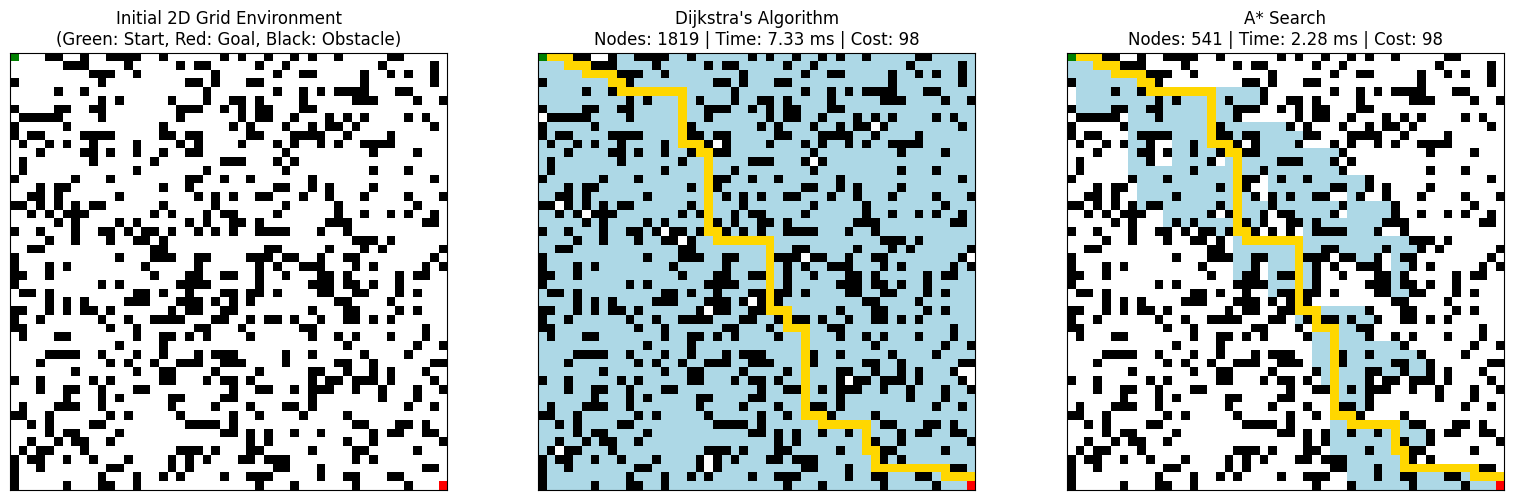

Scenario 2 (50x50)     | Dijkstra | 8.33          | 1852.2     | 98.2     | —
Scenario 2 (50x50)     | A*       | 4.50          | 866.2      | 98.2     | 53.2%
----------------------------------------------------------------------------------
Scenario 3 (100x100)   | Dijkstra | 28.82         | 6838.2     | 199.8    | —
Scenario 3 (100x100)   | A*       | 10.58         | 2164.3     | 199.8    | 68.3%
----------------------------------------------------------------------------------


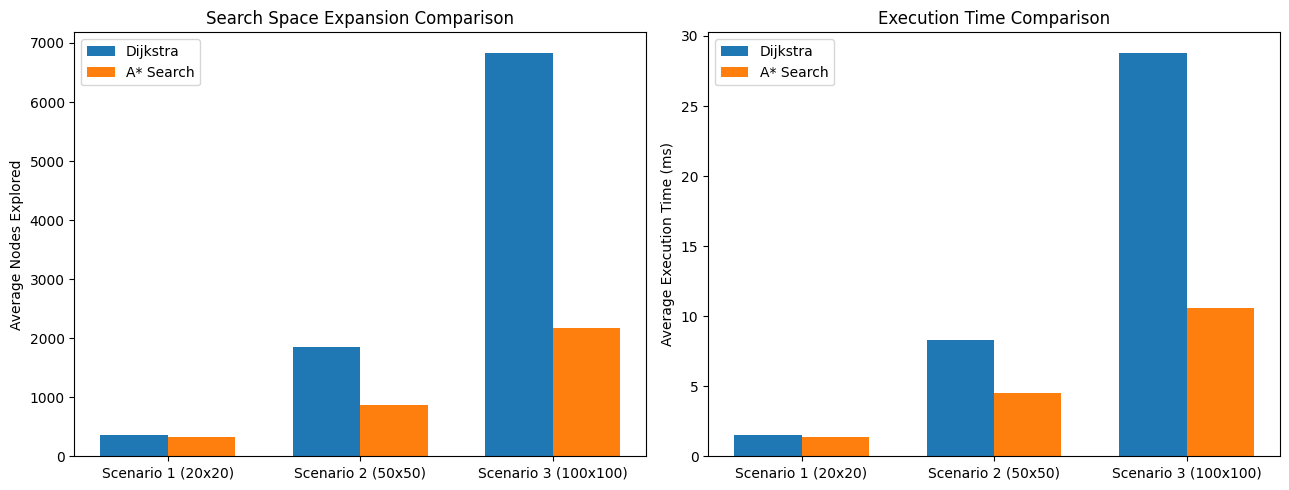

In [22]:
if __name__ == "__main__":
    scenarios = [
        ("Scenario 1 (20x20)", 20, 0.10),
        ("Scenario 2 (50x50)", 50, 0.25),
        ("Scenario 3 (100x100)", 100, 0.30)
    ]

    trials_per_scenario = 10
    summary_results = []

    print(f"{'Scenario':<22} | {'Algo':<8} | {'Avg Time (ms)':<13} | {'Avg Nodes':<10} | {'Avg Cost':<8} | {'Reduction'}")
    print("-" * 82)

    for label, size, density in scenarios:
        d_times, d_nodes_list, d_costs = [], [], []
        a_times, a_nodes_list, a_costs = [], [], []

        seed_counter = 100
        valid_trials = 0

        # Ensure we collect 10 solvable grid trials per scenario
        while valid_trials < trials_per_scenario:
            grid, start, goal = create_grid(size=size, obstacle_prob=density, seed=seed_counter)
            seed_counter += 1

            d_path, d_vis, d_n, d_t = run_search(grid, start, goal, use_astar=False)
            a_path, a_vis, a_n, a_t = run_search(grid, start, goal, use_astar=True)

            if d_path is not None and a_path is not None:
                valid_trials += 1
                d_times.append(d_t)
                d_nodes_list.append(d_n)
                d_costs.append(len(d_path) - 1)

                a_times.append(a_t)
                a_nodes_list.append(a_n)
                a_costs.append(len(a_path) - 1)

                # Save visual comparison on the first valid 50x50 grid
                if size == 50 and valid_trials == 1:
                    visualize_grid_comparison(grid, start, goal, (d_path, d_vis, d_n, d_t), (a_path, a_vis, a_n, a_t))

        avg_d_time, avg_a_time = np.mean(d_times), np.mean(a_times)
        avg_d_nodes, avg_a_nodes = np.mean(d_nodes_list), np.mean(a_nodes_list)
        avg_d_cost, avg_a_cost = np.mean(d_costs), np.mean(a_costs)
        reduction = ((avg_d_nodes - avg_a_nodes) / avg_d_nodes) * 100

        print(f"{label:<22} | {'Dijkstra':<8} | {avg_d_time:<13.2f} | {avg_d_nodes:<10.1f} | {avg_d_cost:<8.1f} | —")
        print(f"{label:<22} | {'A*':<8} | {avg_a_time:<13.2f} | {avg_a_nodes:<10.1f} | {avg_a_cost:<8.1f} | {reduction:.1f}%")
        print("-" * 82)

        summary_results.append({
            'label': label,
            'd_nodes': avg_d_nodes,
            'a_nodes': avg_a_nodes,
            'd_time': avg_d_time,
            'a_time': avg_a_time
        })

    plot_benchmark_charts(summary_results)